In [9]:
print("Uber Fare Prediction")

Uber Fare Prediction


In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [11]:
df = pd.read_csv("uber.csv")

print("First 5 Records:")
display(df.head())

print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nMissing Values:")
print(df.isnull().sum())

df.info()

First 5 Records:


,Unnamed: 0,key,fare_amount,pickup_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
0,24238194,2015-05-07 19:52:06.0000003,7.5,2015-05-07 19:52:06 UTC,-73.999817,40.738354,-73.999512,40.723217,1
1,27835199,2009-07-17 20:04:56.0000002,7.7,2009-07-17 20:04:56 UTC,-73.994355,40.728225,-73.994710,40.750325,1
2,44984355,2009-08-24 21:45:00.00000061,12.9,2009-08-24 21:45:00 UTC,-74.005043,40.740770,-73.962565,40.772647,1
3,25894730,2009-06-26 08:22:21.0000001,5.3,2009-06-26 08:22:21 UTC,-73.976124,40.790844,-73.965316,40.803349,3
4,17610152,2014-08-28 17:47:00.000000188,16.0,2014-08-28 17:47:00 UTC,-73.925023,40.744085,-73.973082,40.761247,5


Dataset Shape: (200000, 9)

Column Names:
['Unnamed: 0', 'key', 'fare_amount', 'pickup_datetime', 'pickup_longitude', 'pickup_latitude', 'dropoff_longitude', 'dropoff_latitude', 'passenger_count']

Missing Values:
Unnamed: 0           0
key                  0
fare_amount          0
pickup_datetime      0
pickup_longitude     0
pickup_latitude      0
dropoff_longitude    1
dropoff_latitude     1
passenger_count      0
dtype: int64
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200000 entries, 0 to 199999
Data columns (total 9 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   Unnamed: 0         200000 non-null  int64  
 1   key                200000 non-null  object 
 2   fare_amount        200000 non-null  float64
 3   pickup_datetime    200000 non-null  object 
 4   pickup_longitude   200000 non-null  float64
 5   pickup_latitude    200000 non-null  float64
 6   dropoff_longitude  199999 non-null  float64
 7   dropoff_la

In [12]:
df = df.dropna()

df["pickup_datetime"] = pd.to_datetime(
    df["pickup_datetime"], errors="coerce"
)

df = df.dropna(subset=["pickup_datetime"])

df["hour"] = df["pickup_datetime"].dt.hour
df["day"] = df["pickup_datetime"].dt.day
df["month"] = df["pickup_datetime"].dt.month
df["year"] = df["pickup_datetime"].dt.year
df["day_of_week"] = df["pickup_datetime"].dt.dayofweek

df = df.drop("pickup_datetime", axis=1)

if "key" in df.columns:
    df = df.drop("key", axis=1)

print("After Preprocessing:")
display(df.head())

After Preprocessing:


,Unnamed: 0,fare_amount,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count,hour,day,month,year,day_of_week
0,24238194,7.5,-73.999817,40.738354,-73.999512,40.723217,1,19,7,5,2015,3
1,27835199,7.7,-73.994355,40.728225,-73.994710,40.750325,1,20,17,7,2009,4
2,44984355,12.9,-74.005043,40.740770,-73.962565,40.772647,1,21,24,8,2009,0
3,25894730,5.3,-73.976124,40.790844,-73.965316,40.803349,3,8,26,6,2009,4
4,17610152,16.0,-73.925023,40.744085,-73.973082,40.761247,5,17,28,8,2014,3


In [13]:
df = df[df["fare_amount"] > 0]
df = df[df["passenger_count"] > 0]

df = df[
    (df["pickup_latitude"].between(-90, 90)) &
    (df["dropoff_latitude"].between(-90, 90)) &
    (df["pickup_longitude"].between(-180, 180)) &
    (df["dropoff_longitude"].between(-180, 180))
]

print("Shape after removing invalid values:")
print(df.shape)

Shape after removing invalid values:
(199257, 12)


In [14]:
Q1 = df["fare_amount"].quantile(0.25)
Q3 = df["fare_amount"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = df[
    (df["fare_amount"] < lower_bound) |
    (df["fare_amount"] > upper_bound)
]

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)
print("Number of Outliers:", len(outliers))

Q1: 6.0
Q3: 12.5
IQR: 6.5
Lower Bound: -3.75
Upper Bound: 22.25
Number of Outliers: 17120


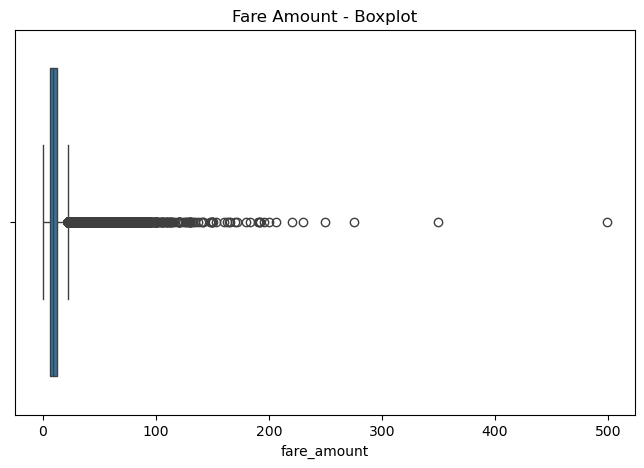

Shape after removing outliers:
(182137, 12)


In [15]:
plt.figure(figsize=(8, 5))

sns.boxplot(x=df["fare_amount"])

plt.title("Fare Amount - Boxplot")
plt.show()

df = df[
    (df["fare_amount"] >= lower_bound) &
    (df["fare_amount"] <= upper_bound)
]

print("Shape after removing outliers:")
print(df.shape)

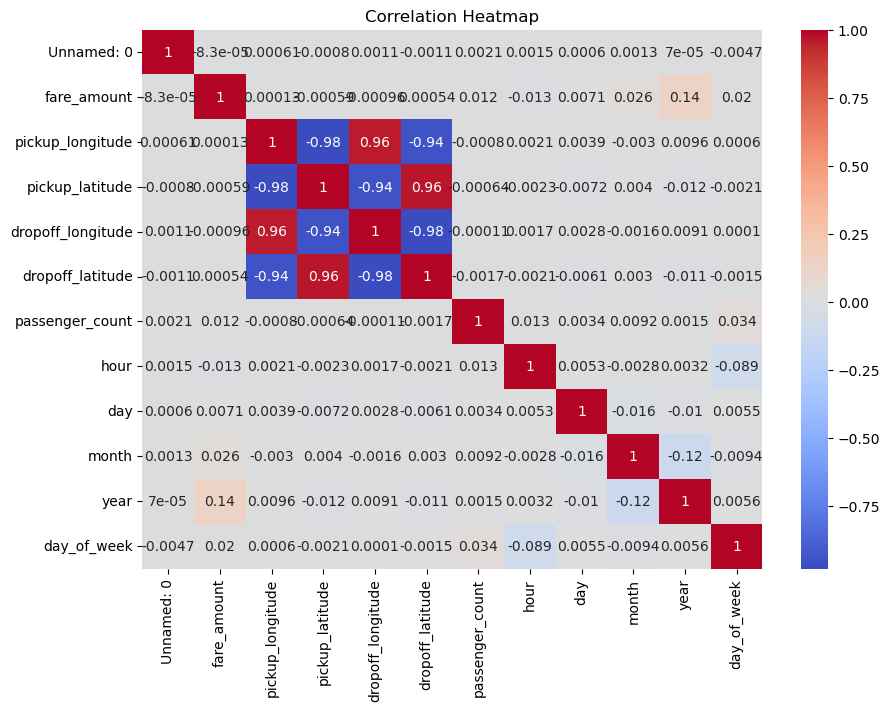

In [16]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    df.corr(numeric_only=True),
    annot=True,
    cmap="coolwarm"
)

plt.title("Correlation Heatmap")
plt.show()

In [17]:
X = df.drop("fare_amount", axis=1)
y = df["fare_amount"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (145709, 11)
Testing Data: (36428, 11)


In [18]:
lr = LinearRegression()

lr.fit(X_train, y_train)

lr_pred = lr.predict(X_test)

print("Linear Regression Completed!")

Linear Regression Completed!


In [19]:
rf = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf.fit(X_train, y_train)

rf_pred = rf.predict(X_test)

print("Random Forest Regression Completed!")

Random Forest Regression Completed!


In [20]:
print("Linear Regression Results")

print("MAE:", mean_absolute_error(y_test, lr_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, lr_pred)))
print("R2 Score:", r2_score(y_test, lr_pred))

print("\nRandom Forest Results")

print("MAE:", mean_absolute_error(y_test, rf_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, rf_pred)))
print("R2 Score:", r2_score(y_test, rf_pred))

Linear Regression Results
MAE: 3.2414398865341454
RMSE: 4.095731560497755
R2 Score: 0.019834537950210507

Random Forest Results
MAE: 1.3974573816844185
RMSE: 2.0316649463540273
R2 Score: 0.7588203831404094


In [21]:
results = pd.DataFrame({
    "Model": ["Linear Regression", "Random Forest"],
    "MAE": [
        mean_absolute_error(y_test, lr_pred),
        mean_absolute_error(y_test, rf_pred)
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(y_test, lr_pred)),
        np.sqrt(mean_squared_error(y_test, rf_pred))
    ],
    "R2 Score": [
        r2_score(y_test, lr_pred),
        r2_score(y_test, rf_pred)
    ]
})

display(results)

,Model,MAE,RMSE,R2 Score
0,Linear Regression,3.241440,4.095732,0.019835
1,Random Forest,1.397457,2.031665,0.758820
